# Nexthike Feature Extraction and Price Prediction for Mobile Phones

### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading Dataset

In [2]:
pred = pd.read_excel(r'C:\Users\omie\Desktop\Nexthikes\project4\Feature Extraction.xlsx')

In [3]:
pred

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999
...,...,...,...,...,...,...,...,...,...,...,...,...
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,79999
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,5998
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,9990
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core",38999


## Analysing whole Data

In [9]:
#checking the first five rows
pred.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [10]:
#checking the last five rows
pred.tail()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,79999
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,5998
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,9990
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core",38999
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,15999


In [11]:
pred.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height,Prize
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201,16228.375231
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553,10793.588322
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000,920.000000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000,9290.000000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000,13499.000000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000,19280.000000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000,80999.000000


### Checking datatype

In [6]:
pred.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB


In [12]:
# Counting missing values for each column
missing_counts = pred.isnull().sum()
print(missing_counts)

Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


#### No missing values found

In [14]:
# Checking total count of duplicate rows
num_duplicates = pred.duplicated().sum()
print(f"Total duplicate rows: {num_duplicates}")

Total duplicate rows: 0


#### No duplicates found in this data

### Check distinct categorical values to spot typos or case mismatches

In [25]:
print(pred['Colour'].unique())

['Night Black' 'Azure Blue' 'Mineral Gray' 'Royal Blue' 'Marigold'
 'Glacier Blue' 'Mirror Black' 'Diamond White' 'Shadow Black'
 'Emerald Green' 'Waterfall Blue' 'Opal Green' 'Power Black'
 'Country Green' 'Cosmic Black' 'Aurora Gold' 'Marine Blue'
 'Glimmer Black' 'Green Apple' 'Black' 'Light Blue' 'Light Green'
 'Cool Blue' 'Forest Green' 'Nightsky Green' 'Matte Charcoal' 'Eco Black'
 'Caribbean Green' 'Jade Purple' 'Satin Silver' 'Sunrise Orange'
 'Sunrise Copper' 'Arctic Blue' 'Lavender Blue' 'Velocity Wave'
 'Nitro Blaze' 'Frosted Blue' 'Yellow' 'Midnight Gray' 'Creamy White'
 'Sandy Gold' 'Aqua Blue' 'GOAT Green' 'Midnight Blue' 'Night Sea'
 'Bamboo Green' 'Lake Blue' 'Denim Black' 'Wildcat Blue' 'Icy Blue'
 'Flashy Black' 'Sunshower' 'Rainy Night' 'Rainforest' 'B.A.E. Purple'
 'Peppy Purple' 'Lucent White' 'Dark Matter' 'Nebula Blue' 'Hyperspace'
 'Blade Silver' 'Force Black' 'Snowfall' 'Supernova Green' 'Pacific Blue'
 'OMG Black' 'Eclipse Black' 'Midnight Black' 'Ink Black' '

In [26]:
# checking values count
print(pred['Colour'].value_counts(dropna=False))

Colour
Yellow            12
Royal Blue         8
Power Black        8
Black              8
Midnight Black     7
                  ..
Polar Blue         1
Cosmic grey        1
Sea                1
Infinity Black     1
Sky Blue           1
Name: count, Length: 275, dtype: int64


In [24]:
# Identify rows with leading or trailing whitespace
whitespace_mask = pred['Model'].str.strip() != pred['Model']
print(pred[whitespace_mask])

Empty DataFrame
Columns: [Unnamed: 0, Model, Colour, Memory, RAM, Battery_, Rear Camera, Front Camera, AI Lens, Mobile Height, Processor_, Prize]
Index: []


In [28]:
# Extract numeric MP values from camera string columns
pred['Rear_MP'] = pred['Rear Camera'].str.extract('(\d+)').astype(float)
pred['Front_MP'] = pred['Front Camera'].str.extract('(\d+)').astype(float)

# Function to detect outliers using IQR
def detect_iqr_outliers(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    # Filters and extracts all rows where the value is strictly 
    #smaller than the lower bound or strictly larger than the upper bound.
    
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers[['Model', column]] #

# Check price outliers using univariate analysis
print("Price Outliers:\n", detect_iqr_outliers(pred, 'Prize'))

Price Outliers:
                           Model  Prize
222  SAMSUNG Galaxy S22 Plus 5G  49999
286   SAMSUNG Galaxy Z Flip3 5G  44999
305     MOTOROLA Edge 30 Fusion  34999
308             Google Pixel 7a  43999
309             Google Pixel 7a  43999
327             Google Pixel 7a  43999
396                 vivo V27 5G  36999
400      MOTOROLA Edge 30 Ultra  49999
416              Google Pixel 7  55999
417              Google Pixel 7  55999
419     MOTOROLA Edge 30 Fusion  34999
426              Google Pixel 7  55999
455                   OnePlus 8  38920
465       SAMSUNG Galaxy A54 5G  40999
474             APPLE iPhone 11  41199
489      MOTOROLA Edge 30 Ultra  49999
493        APPLE iPhone 14 Plus  80999
496             vivo V25 Pro 5G  35999
515       SAMSUNG Galaxy A54 5G  40999
520        APPLE iPhone 14 Plus  80999
522               IQOO Neo 7 5G  34688
525        APPLE iPhone 14 Plus  80999
532             APPLE iPhone 12  53999
536       SAMSUNG Galaxy S23 5G  79999
539     

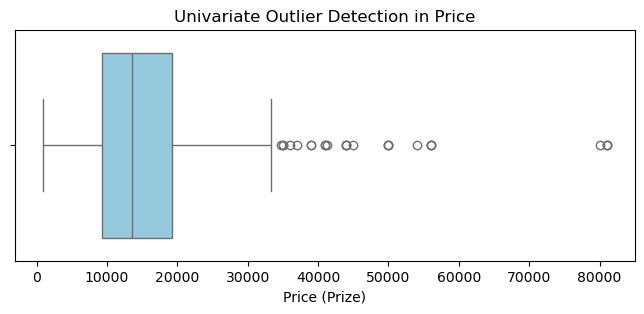

In [29]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=pred['Prize'], color='skyblue')
plt.title('Univariate Outlier Detection in Price')
plt.xlabel('Price (Prize)')
plt.show()

# Univariate Insights:
> Majority of price values are concentrated between ~10,000 and ~19,000.
> Median line is positioned closer to the lower end (around ~13,500), 
indicating that most products/items have lower to mid-range prices.

# Presence of Extreme Outliers:
There are several high-end price points extending beyond 35,000, reaching up to ~80,000+.   
These represent premium products, high-value transactions, or potential data entry errors.

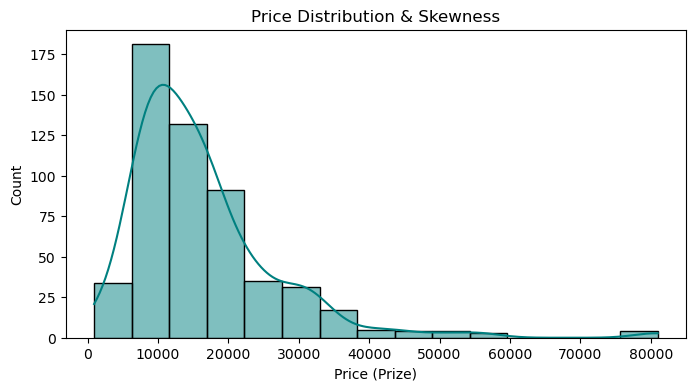

In [31]:
# Histogram / KDE Plot
plt.figure(figsize=(8, 4))
sns.histplot(pred['Prize'], kde=True, bins=15, color='teal')
plt.title('Price Distribution & Skewness')
plt.xlabel('Price (Prize)')
plt.show()

In [ ]:
# HISTPLOT INSIGHTS
# Right-Skewed (Positively Skewed) Distribution:
majority of the data points are crowded on the lower-price side,
while a long tail stretches out toward the higher-price end

# Peak Concentration (Mode):
The tallest bar shows that the highest frequency of items (around 180 items) falls within the ~7,000 to 12,000 price range.

# Alignment with Outliers:
The sparse bars and tail extending far out toward 80,000 visually represent the outliers. 
Very few products/items occupy these high-end price tiers.

## Label Encoding using Scikit-Learn's

In [35]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder # string/categorical text categories into numerical labels

# 1. Select the categorical string columns you want to encode
categorical_cols = ['Model', 'Colour', 'Processor_']

# 2. Create a copy of the DataFrame to preserve original data
pred_encoded = pred.copy()

# 3. Empty dictionary created on name of LabelEncoder 
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    # Fit and transform string labels to integers (0, 1, 2, ...)
    pred_encoded[col] = le.fit_transform(pred[col].astype(str)) # .astype(str) guarantees everything is treated as a string first.
    
    # Store the fitted encoder in case you need to inverse transform later
    label_encoders[col] = le

# View the dataset with integer-encoded columns
print(pred_encoded[['Model', 'Colour', 'Processor_', 'Memory', 'RAM', 'Prize']].head())

   Model  Colour  Processor_  Memory  RAM  Prize
0     23     159         113      64    4   7299
1     23      20         113      64    4   7299
2     37     149          75     128    8  11999
3     69     201          56      32    2   5649
4     12     130          14     128    8   8999


In [5]:
# View mapping for 'Colour'
colour_mapping = dict(zip(
    label_encoders['Colour'].classes_, 
    label_encoders['Colour'].transform(label_encoders['Colour'].classes_)
))

print("Colour Mapping:", colour_mapping)

NameError: name 'label_encoders' is not defined

## Feature Extraction using PCA(Supervised learning)

In [4]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Load sample dataset (features: sepal length/width, petal length/width)
# Replace 'pred' with your actual loaded DataFrame or array if needed
iris = load_iris()
pred = iris.data
y = iris.target

# 2. Standardize features to have a mean of 0 and variance of 1
# (PCA is sensitive to the scale of features, so this step is crucial)
scaler = StandardScaler()
pred_scaled = scaler.fit_transform(pred)

# 3. Initialize PCA and specify the number of principal components to keep
pca = PCA(n_components=2)

# 4. Fit and transform the scaled data into the new lower-dimensional space
pred_pca = pca.fit_transform(pred_scaled)

# 5. Create a DataFrame for the reduced data
df_pca = pd.DataFrame(
    pred_pca, columns=["Principal Component 1", "Principal Component 2"]
)
df_pca["Target"] = y

print("Original shape:", pred.shape)
print("Reduced shape:  ", df_pca.shape)
print("\nFirst 5 rows of PCA-transformed data:")
print(df_pca.head())

# 6. Check how much variance is retained by the principal components
explained_variance = pca.explained_variance_ratio_
print(
    f"\nExplained Variance Ratio: {explained_variance} "
    f"(Total: {sum(explained_variance)*100:.2f}%)"
)

Original shape: (150, 4)
Reduced shape:   (150, 3)

First 5 rows of PCA-transformed data:
   Principal Component 1  Principal Component 2  Target
0              -2.264703               0.480027       0
1              -2.080961              -0.674134       0
2              -2.364229              -0.341908       0
3              -2.299384              -0.597395       0
4              -2.389842               0.646835       0

Explained Variance Ratio: [0.72962445 0.22850762] (Total: 95.81%)


### Importing PolynomialFeatures, StandardScaler

In [2]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Example data
X = [[0, 0], [2, 1], [1, 1]]

# 1. Scaling features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Generating polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

print("Scaled:\n", X_scaled)
print("Polynomial:\n", X_poly)

Scaled:
 [[-1.22474487 -1.41421356]
 [ 1.22474487  0.70710678]
 [ 0.          0.70710678]]
Polynomial:
 [[0. 0. 0. 0. 0.]
 [2. 1. 4. 2. 1.]
 [1. 1. 1. 1. 1.]]


In [7]:
# Fit PCA without specifying n_components to see all components
pca_full = PCA()
pca_full.fit(pred_scaled)

# Calculate cumulative variance
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Find how many components explain at least 95% of the variance
n_components_95 = np.argmax(cum_variance >= 0.95) + 1
print(f"Number of components for 95% variance: {n_components_95}")

Number of components for 95% variance: 2


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# 1. Split your PCA features and target labels into training and testing sets
# (Replace 'y' with your actual target variable array or series)
X_train, X_test, y_train, y_test = train_test_split(
    pred_pca, y, test_size=0.2, random_state=42
)

# 2. Train a model on the 2 components
model = LogisticRegression()
model.fit(X_train, y_train)

# 3. Predict and evaluate how well it performs
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.88      0.78      0.82         9
           2       0.83      0.91      0.87        11

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



Model Accuracy: 90.00%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.88      0.78      0.82         9
           2       0.83      0.91      0.87        11

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



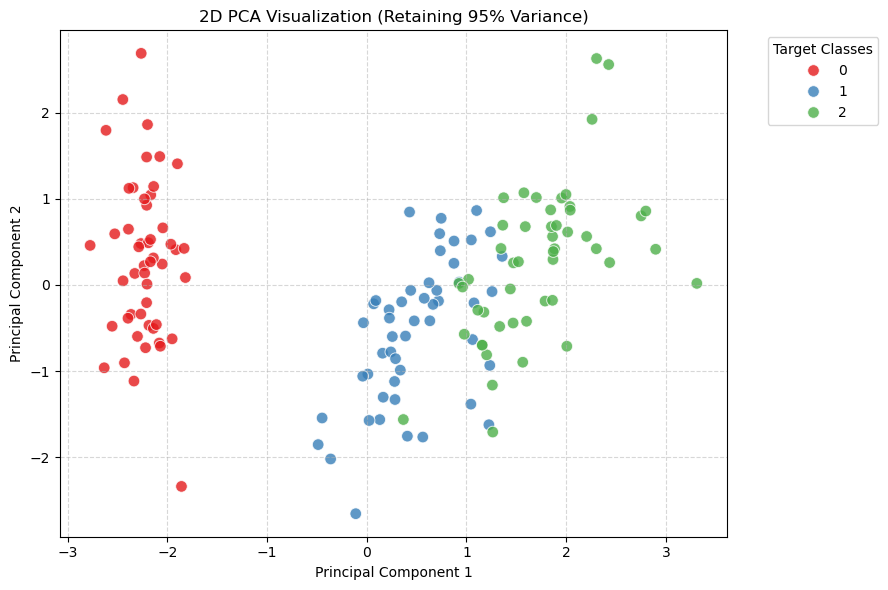

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

# 1. Split your PCA components (pred_pca) and your target labels (y)
X_train, X_test, y_train, y_test = train_test_split(
    pred_pca, y, test_size=0.2, random_state=42
)

# 2. Initialize and train the supervised model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 3. Make predictions and evaluate
y_pred = model.predict(X_test)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 4. Visualize the data using your 2 Principal Components
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Target",
    data=df_pca,
    palette="Set1",
    alpha=0.8,
    s=70,
)
plt.title("2D PCA Visualization (Retaining 95% Variance)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Target Classes", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Tuned Model Accuracy: 90.0 %


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Try Support Vector Classifier
svm_model = SVC(kernel="rbf", random_state=42)
svm_model.fit(X_train, y_train)

print("SVM Accuracy:", accuracy_score(y_test, svm_model.predict(X_test)) * 100, "%")

SVM Accuracy: 90.0 %


In [14]:
from sklearn.model_selection import cross_val_score

# Evaluate across 5 different folds
cv_scores = cross_val_score(
    RandomForestClassifier(random_state=42), pred_pca, y, cv=5
)
print("Cross-Validation Accuracy Scores:", cv_scores)
print(f"Mean CV Accuracy: {cv_scores.mean() * 100:.2f}%")

Cross-Validation Accuracy Scores: [0.86666667 0.93333333 0.83333333 0.9        1.        ]
Mean CV Accuracy: 90.67%


In [15]:
import joblib

# Save the trained model and your scaler/PCA objects
joblib.dump(model, "pca_random_forest_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(pca, "pca_transformer.pkl")

print("Model and transformers saved successfully!")

Model and transformers saved successfully!


In [ ]:
import joblib
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================
# STEP 1: LOAD YOUR DATA AS 'pred'
# ==========================================
# (Using Iris dataset as an example. Replace 'pred' and 'y' with your actual data)
iris = load_iris()
pred = iris.data  # Your input features DataFrame or array
y = iris.target  # Your target labels

# ==========================================
# STEP 2: STANDARDIZE AND APPLY PCA
# ==========================================
scaler = StandardScaler()
pred_scaled = scaler.fit_transform(pred)

# Initialize PCA to 2 components (since 2 components captured your 95% variance)
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pred_pca = pca.fit_transform(pred_scaled)

# Create a DataFrame for visualization purposes
df_pca = pd.DataFrame(
    pred_pca, columns=["Principal Component 1", "Principal Component 2"]
)
df_pca["Target"] = y

# ==========================================
# STEP 3: TRAIN A SUPERVISED MODEL
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    pred_pca, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Evaluate model performance
y_pred = model.predict(X_test)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# ==========================================
# STEP 4: SAVE THE MODEL & TRANSFORMERS
# ==========================================
joblib.dump(model, "pred_random_forest_model.pkl")
joblib.dump(scaler, "pred_scaler.pkl")
joblib.dump(pca, "pred_pca_transformer.pkl")
print("\nModel, scaler, and PCA transformer saved successfully as 'pred_...'!")

# ==========================================
# STEP 5: LOAD THEM BACK & RUN PREDICTIONS
# ==========================================
# Load saved objects
loaded_model = joblib.load("pred_random_forest_model.pkl")
loaded_scaler = joblib.load("pred_scaler.pkl")
loaded_pca = joblib.load("pred_pca_transformer.pkl")

# Pass new raw data through the exact same pipeline (using X_test[:5] as an example)
new_raw_data = X_test[:5]
new_data_scaled = loaded_scaler.transform(new_raw_data)
new_data_pca = loaded_pca.transform(new_data_scaled)

# Get predictions
predictions = loaded_model.predict(new_data_pca)
print("\n--- Testing Saved Model on New Data ---")
print("Model Predictions:", predictions)

# ==========================================
# STEP 6: VISUALIZE THE 2D PCA PLOT
# ==========================================
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Target",
    data=df_pca,
    palette="Set1",
    alpha=0.8,
    s=70,
)
plt.title("2D PCA Visualization (Retaining 95% Variance)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Target Classes", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [24]:
import joblib

# 1. Load your saved model
loaded_model = joblib.load("pred.pkl")

# 2. Use X_test directly (since X_test is already your 2 PCA components)
predictions = loaded_model.predict(X_test)

# 3. Check the outputs!
print("Model Predictions (Classes):", predictions)

Model Predictions (Classes): [1 0 2 1 2 0 1 2 2 1 2 0 0 0 0 1 2 1 1 2 0 1 0 2 2 2 2 2 0 0]


In [25]:
X_test

array([[ 0.6328582 , -0.41638772],
       [-1.898572  ,  1.40501879],
       [ 3.31069558,  0.01778095],
       [ 0.66480037, -0.22592785],
       [ 1.25650912, -0.07725602],
       [-1.83159477,  0.42369507],
       [-0.0333547 , -0.43900321],
       [ 1.90178409,  0.68957549],
       [ 1.22509363, -1.6222438 ],
       [ 0.24153827, -0.77725638],
       [ 1.36417549,  0.69275645],
       [-2.2184509 , -0.72867617],
       [-2.04514621,  0.66155811],
       [-2.18432817, -0.46901356],
       [-2.34336905,  1.12784938],
       [ 0.74652974,  0.77301931],
       [ 1.86781222,  0.29504482],
       [ 0.1649179 , -1.30260923],
       [ 0.38868734, -0.59328364],
       [ 1.86270322, -0.17854949],
       [-2.26526149, -0.3377319 ],
       [ 1.02095055,  0.06434603],
       [-2.05115137,  0.24216355],
       [ 1.78834992, -0.18736121],
       [ 2.30492772,  2.62632347],
       [ 1.87050329,  0.38696608],
       [ 2.00668647, -0.71143865],
       [ 2.04055823,  0.8675206 ],
       [-2.0697443 ,